# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Alumno**: Facundo Ortega

**Legajo**: 65560 

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.5.1+cpu


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [2]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 5s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


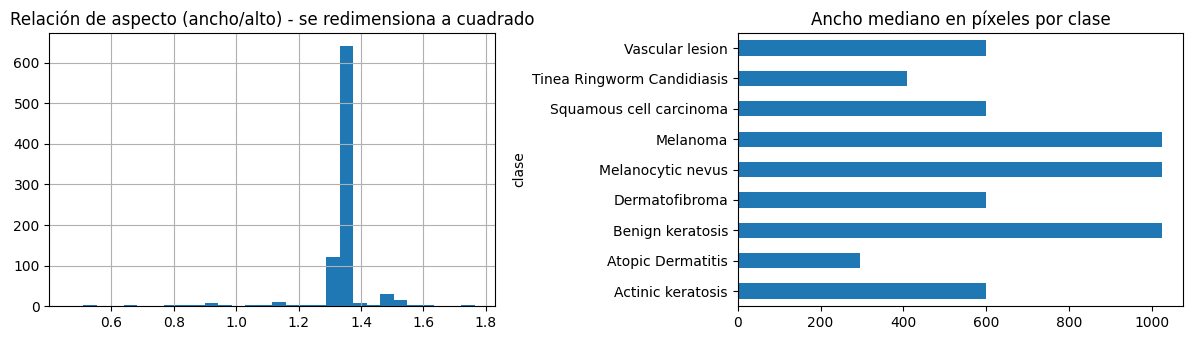

In [3]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

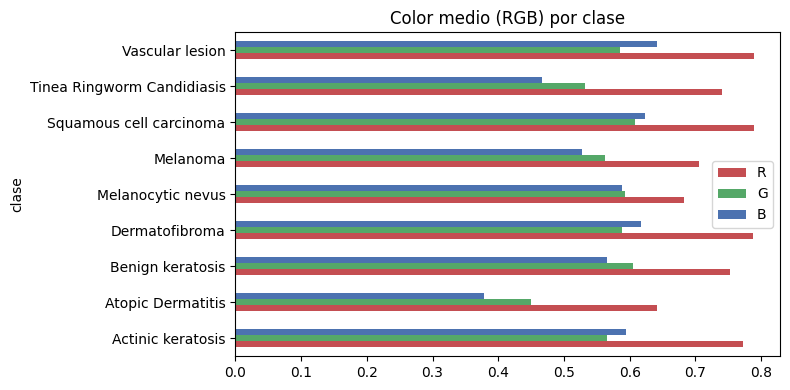

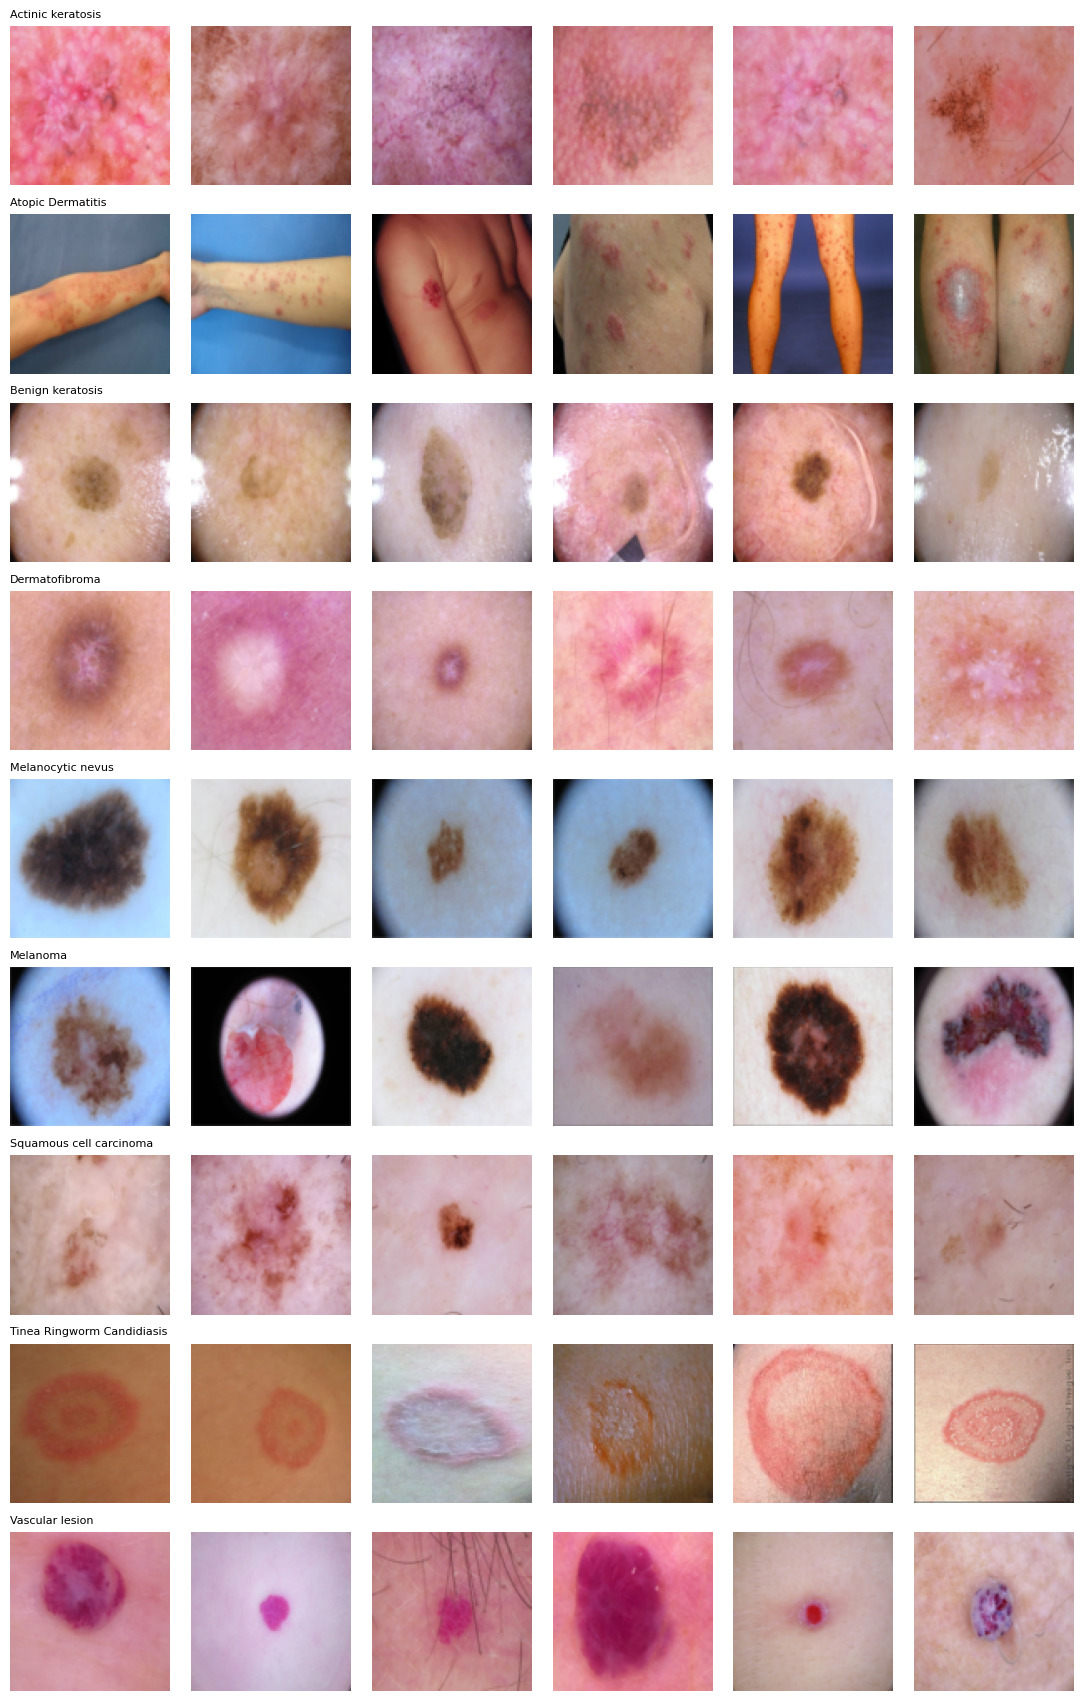

In [4]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [5]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA

**1. Desbalance.** El dataset trae 878 imágenes. Ocho clases tienen alrededor de 100 imágenes cada una (80 en `train/` y 20 en `val/`; Atopic Dermatitis tiene 81 + 21 = 102). La excepción es Tinea Ringworm Candidiasis, con 76 (56 + 20). El desbalance es leve: la clase más chica tiene ~75% de las imágenes de las demás. Lo que cambia la composición es la **eliminación de duplicados**, que se concentra en dos clases: quedan 844 imágenes, con Atopic Dermatitis en 80 y Tinea en 64. Esas dos pasan a ser las clases minoritarias (≈ 8–9% del total cada una, contra ≈ 12% del resto). La partición original `train/`/`val/` se descarta: tiene imágenes repetidas entre carpetas y no tiene test. En su lugar se hace un split estratificado 60/20/20: train 506, val 169 y test 169 imágenes. Las proporciones se conservan en las tres particiones (60/20/20 por clase en las clases completas; Atopic 48/16/16 y Tinea 38/13/13).

**2. Resolución, aspecto y color: la clase se puede adivinar por la fuente de la imagen.**
- **Resolución.** Es casi una etiqueta:
  - 600×450: el 100% de Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion (las 400 imágenes con esa resolución).
  - 294×222: el 100% de Atopic Dermatitis (102 imágenes).
  - Benign keratosis: 74% en 1024×764.
  - Melanocytic nevus: 79% en 1024×768 y 18% en 1022×767.
  - Melanoma: 56% en 1024×768 y 41% en otras resoluciones.
  - Tinea: 100% en resoluciones variadas.

  El ancho mediano va de 294 px (Atopic) a 1024 px (BK, nevus, melanoma).
- **Aspecto.** Casi todas las imágenes son 4:3 (mediana 1.333), con algunas excepciones entre 0.47 y 1.77. Al redimensionar a cuadrado, todas se deforman.
- **Color.** Atopic Dermatitis (R 0.64, G 0.45, **B 0.38**) y Tinea (B 0.47) son claramente más oscuras y menos azuladas que las lesiones dermatoscópicas (B ≈ 0.53–0.64). Los ejemplos muestran que son **fotos clínicas** de piel y no dermatoscopías, con otro encuadre y otra iluminación.

**Riesgo.** El modelo ve imágenes redimensionadas, así que no conoce la resolución original. Pero esa resolución deja rastros que sí ve: la nitidez (una imagen de 294 px reescalada se ve distinta a una de 1024 px), los artefactos de compresión, el encuadre, el color de fondo y el tipo de cámara. La red puede aprender a reconocer **la fuente o el tipo de foto** en vez de la lesión (*shortcut learning*). Eso aumentaría la accuracy en este dataset sin que el modelo haya aprendido a distinguir las lesiones, y no generalizaría a imágenes de otra fuente: la métrica sobreestimaría el rendimiento real. Esto es particularmente probable para Atopic Dermatitis y Tinea, que son las únicas fotos clínicas. 

**3. Duplicados.**
- Hay **34 pares de imágenes idénticas** (mismo MD5): 22 de Atopic Dermatitis y 12 de Tinea.
- **33 de esos pares están repartidos entre `train/` y `val/`**; el par restante está dentro de `train/`.
- No hay conflictos de etiqueta: cada copia tiene la misma clase.
- El hash perceptual encuentra 34 pares casi iguales, y **los 34 son los mismos duplicados exactos**: no hay recortes ni recompresiones adicionales.

Esto importa porque **las 21 imágenes de Atopic Dermatitis de `val/` y 12 de las 20 de Tinea ya estaban en `train/`**: el 18% de la validación original (33 de 181 imágenes) eran imágenes vistas durante el entrenamiento. Si no se eliminaran, la `val_acc` mediría en parte **memoria** y no generalización. Saldría inflada, sobre todo en esas dos clases (donde el modelo podría acertar las imágenes repetidas por haberlas visto), y las decisiones tomadas con validación (arquitectura, augmentation, early stopping) estarían sesgadas a favor de los modelos que más memorizan. Es decir, se estaría evaluando a la red con imágenes que ya vio durante el entrenamiento.


## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [6]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

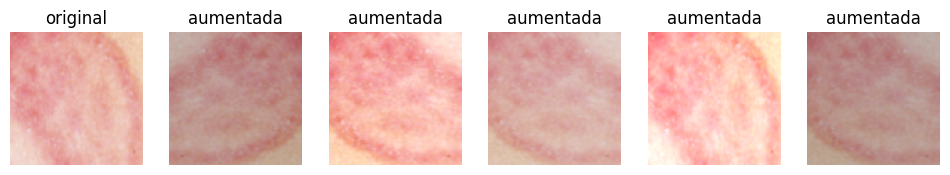

In [7]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [8]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [9]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL

**1. `padding=kernel // 2`.** Con stride 1, el lado de salida de una convolución es $W_o = W - k + 2p + 1$. Con $k = 3$ y $p = 3 // 2 = 1$ queda $W_o = W$: la convolución **no cambia el alto ni el ancho** (padding *same*). Con `padding=0` cada convolución recortaría $k-1 = 2$ píxeles por lado de la imagen completa (64 → 62), los bordes participarían en menos ventanas y la fórmula `fs = size // 2 ** n_blocks` de la cabeza dejaría de valer. En la tabla se ve que cada `Conv2d` conserva el lado de su entrada: (3, 64, 64) → **(16, 64, 64)**, (16, 32, 32) → **(32, 32, 32)**, (32, 16, 16) → **(64, 16, 16)**; solo cambia la cantidad de canales.

**2. `MaxPool2d(2)`.** Toma ventanas de 2×2 sin solapamiento (stride 2) y se queda con el máximo de cada una, canal por canal: **divide el alto y el ancho por 2 y no cambia los canales** (64 → 32 → 16 → 8 en la tabla), y no tiene parámetros (0 en la tabla). Conserva la respuesta más fuerte de cada filtro en cada zona ("el patrón apareció acá cerca") y descarta su posición exacta dentro de la ventana, lo que da algo de invarianza a traslaciones pequeñas. Como cada bloque tiene un pooling y la convolución no cambia el tamaño, después de `n_blocks` bloques el lado es `size // 2 ** n_blocks` = 64 // 8 = **8**, que es exactamente el `fs` que usa la primera `Linear` para saber cuántas entradas recibe (64 canales × 8 × 8 = 4.096 tras el `Flatten`).

**3. Parámetros.**
- Segunda `Conv2d` (16 → 32 canales, kernel 3, sin bias): cada uno de los 32 filtros tiene 3 × 3 × 16 pesos → $3\cdot3\cdot16\cdot32 = $ **4.608** parámetros (la tabla da 4.608). Con bias serían 4.640.
- Primera `Linear` de la cabeza: recibe $64\cdot8\cdot8 = 4.096$ entradas y tiene 128 salidas → $4.096\cdot128 + 128 = $ **524.416** parámetros (coincide con la tabla).
- La `Linear` **domina el total**: 524.416 de 549.273 parámetros (**95,5%**), contra 23.472 de las tres convoluciones juntas (432 + 4.608 + 18.432). La convolución comparte un mismo filtro de 3×3 en todas las posiciones y conecta cada salida solo a una ventana local, así que sus parámetros no dependen del tamaño de la imagen; la `Linear`, en cambio, conecta **cada** valor del mapa aplanado con cada neurona, y su tamaño crece con canales × alto × ancho del último mapa.

**4. `bias=not use_bn`.** La BatchNorm resta la media de cada canal sobre el batch: cualquier constante $b$ sumada por la convolución se cancela exactamente ($\text{BN}(Wx + b) = \text{BN}(Wx)$). Después la BN suma su propio desplazamiento entrenable $\beta$, que cumple el rol del sesgo. Un bias en la convolución sería un parámetro redundante (no cambia la salida y su gradiente es 0). En la tabla, cada `BatchNorm2d` tiene $2 \times$ canales parámetros ($\gamma$ y $\beta$): 32, 64 y 128.

**5. `filters * 2 ** b`.** Cada bloque divide el área espacial por 4 (lado / 2) y duplica los canales (16 → 32 → 64). Así: (a) el costo de cómputo por bloque se mantiene parecido (menos posiciones, más filtros); (b) se compensa la pérdida de resolución con más "tipos" de features: las capas profundas tienen campo receptivo mayor y representan patrones más complejos y variados (combinaciones de bordes → texturas → partes de la lesión), que necesitan más canales para describirse, mientras que la posición exacta importa menos.

**6. `rf_full` (campo receptivo).** Se recorre la red llevando el campo receptivo $r$ y el "salto" $j$ (distancia en píxeles de la imagen entre dos posiciones vecinas del mapa actual). Cada convolución suma $(k-1)\cdot j$; cada maxpool de 2 suma $1\cdot j$ y duplica $j$:

| Capa | suma | $r$ | $j$ |
|---|---|---|---|
| inicio | | 1 | 1 |
| conv 1 (k=3) | +2·1 | 3 | 1 |
| pool 1 | +1·1 | 4 | 2 |
| conv 2 | +2·2 | 8 | 2 |
| pool 2 | +1·2 | 10 | 4 |
| conv 3 | +2·4 | **18** | 4 |

(La función no cuenta el último pooling, que coincide con la definición "campo receptivo de la última conv".) Significa que cada valor del último mapa convolucional "ve" una ventana de **18 × 18 px** de la imagen de entrada, es decir ~28% del lado de una imagen de 64 px (~8% del área). Ninguna neurona convolucional ve la lesión completa: los filtros detectan patrones locales (bordes, texturas, puntos de pigmento) y recién la `Linear` de la cabeza, que mira todo el mapa de 8 × 8, puede combinar información de toda la imagen (forma global, asimetría).


### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 11 | val_acc 0.592 | train_acc 0.862 | 0.44 s/época | total 18s


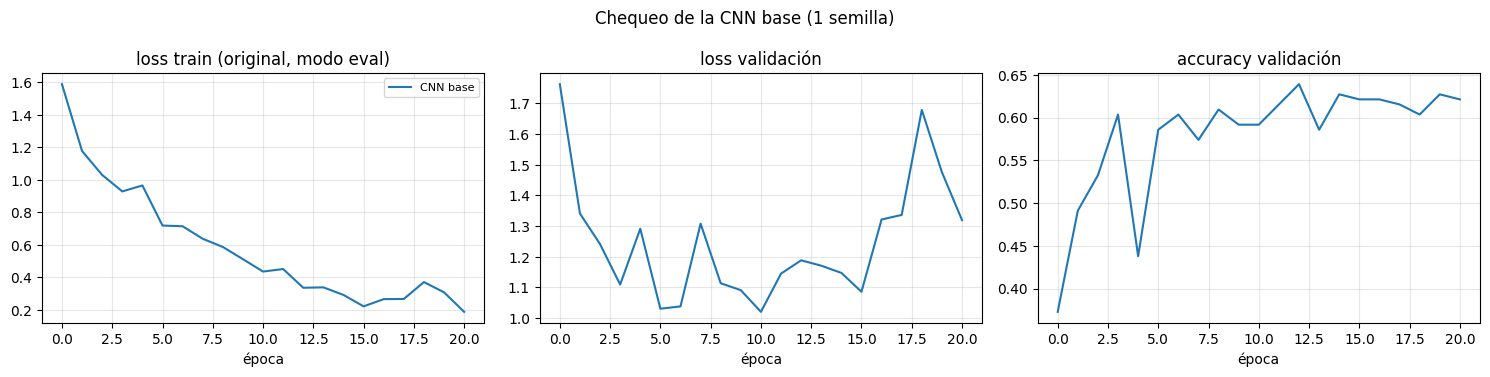

In [10]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.1043,0.4346,0.0605
1,MLP 64px,6358793,0.5266,0.0461,0.7049,0.1782,6.6667,0.4477,0.4254,0.1012
2,CNN 32px,156057,0.6489,0.0343,0.8267,0.1778,10.3333,0.1188,0.5575,0.0914
3,CNN 64px,549273,0.6114,0.0170,0.9071,0.2957,17.3333,0.4034,0.5371,0.0743


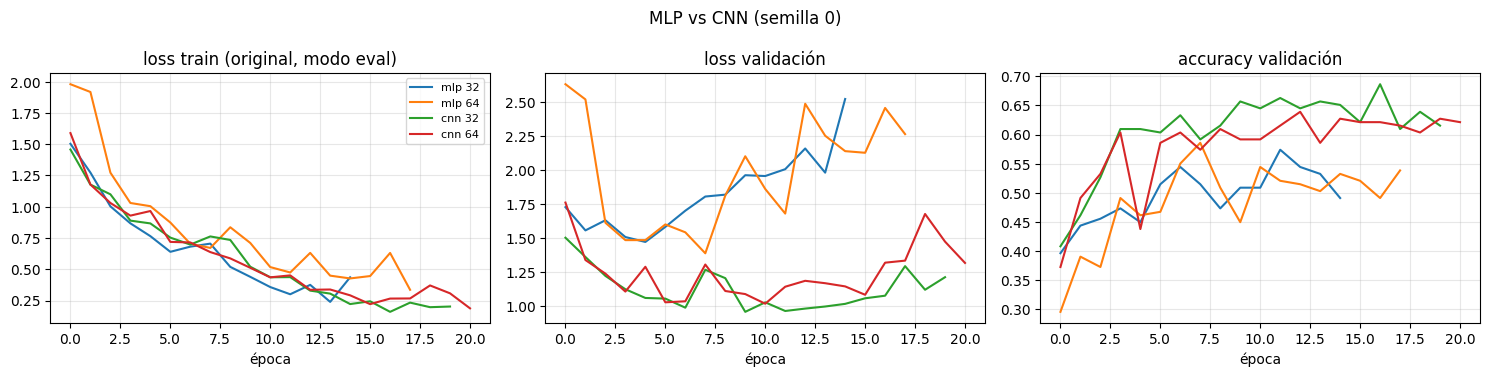

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [11]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN

**1. Comparación (media ± desvío de 3 semillas).**

| Modelo | Parámetros | val_acc | train_acc | Brecha | Mejor época | s/época |
|---|---|---|---|---|---|---|
| MLP 32 px | 1.640.201 | 0.495 ± 0.039 | 0.738 | 0.243 | 5.0 | 0.10 |
| MLP 64 px | 6.358.793 | 0.527 ± 0.046 | 0.705 | 0.178 | 6.7 | 0.45 |
| CNN 32 px | **156.057** | **0.649 ± 0.034** | 0.827 | 0.178 | 10.3 | 0.12 |
| CNN 64 px | 549.273 | 0.611 ± 0.017 | 0.907 | 0.296 | 17.3 | 0.40 |

- **Parámetros.** La CNN usa **10 veces menos** parámetros que la MLP a 32 px (156 k contra 1,64 M) y **12 veces menos** a 64 px (549 k contra 6,36 M).
- **Accuracy.** La CNN es mejor a ambas resoluciones: **+15,4 puntos** a 32 px y **+8,5** a 64 px. Las dos diferencias superan holgadamente el desvío entre semillas (≤ 0.046) y el error estándar de la validación (±0.038 con 169 imágenes, ~±0.037 para accuracies de 0.5–0.65). La de 32 px es ~4 errores estándar y la de 64 px ~2,2. Las dos MLP apenas superan el 50% (azar = 11%).
- **Brecha.** Todos los modelos sobreajustan. La CNN 64 px tiene la brecha más grande (0.296), pero también la mejor train_acc y una val_acc muy superior a las MLP. La MLP no sobreajusta "menos" porque generalice mejor: no llega a ajustar bien ni el train (0.70–0.74).
- **Convergencia.** La MLP llega a su mejor val_loss en 5–7 épocas y después la val_loss sube rápido (en el gráfico, la MLP 32 px corta en la época 15 con val_loss ≈ 2.5). La CNN sigue mejorando más tiempo (10–17 épocas).
- **Tiempo.** A igual resolución el tiempo por época es similar (0.10 vs 0.12 s a 32 px; 0.45 vs 0.40 s a 64 px). La MLP hace pocas operaciones por parámetro y la CNN muchas por parámetro (cada filtro se aplica en todas las posiciones), así que con 10 veces menos parámetros la CNN cuesta lo mismo de cómputo. Lo que ahorra es memoria y, sobre todo, capacidad de memorizar.

**2. Por qué la MLP necesita tantos parámetros.** La primera capa conecta **cada valor de cada píxel** con cada una de las 512 neuronas: tiene $3 \cdot S^2 \cdot 512 + 512$ parámetros.
- **32 px:** $3.072 \cdot 512 + 512 = $ **1.573.376** (96% de la MLP).
- **64 px:** $12.288 \cdot 512 + 512 = $ **6.291.968** (99%).
- **224 px:** $150.528 \cdot 512 + 512 = $ **77.070.848**. Serían 77 M de parámetros en una sola capa para ~500 imágenes de train: memorización asegurada, además del costo de memoria.

La convolución cambia esto por dos propiedades:
- **Conectividad local:** cada salida depende solo de una ventana de 3×3.
- **Pesos compartidos:** el mismo filtro se aplica en todas las posiciones.

Por eso la primera convolución tiene $3 \cdot 3 \cdot 3 \cdot 16 = 432$ parámetros, **independientemente del tamaño de la imagen**. En la CNN lo que crece con la resolución es la `Linear` de la cabeza (ver análisis 2), no las convoluciones.

**3. Robustez a traslaciones** (validación con desplazamientos circulares aleatorios de hasta ±4 px a 32 px y ±8 px a 64 px).

| | Caída a 32 px | Caída a 64 px |
|---|---|---|
| MLP | 0.061 (12% relativo) | 0.101 (19%) |
| CNN | 0.091 (14%) | 0.074 (12%) |

A 64 px la CNN se degrada menos que la MLP, como predice la teoría. A 32 px pasa lo contrario. Las diferencias entre modelos (2–3 puntos) son menores que el error estándar de la validación (±0.038), así que **el ruido no permite concluir** que un modelo sea más robusto que el otro. Las razones:
- La CNN de este TP es **solo parcialmente invariante**. Las convoluciones son equivariantes, pero tiene 3 poolings (invarianza de unos pocos píxeles) y después un `Flatten` + `Linear` que sí depende de la posición de cada valor del mapa de 8×8. Un desplazamiento de 8 px mueve el contenido una celda entera de ese mapa.
- El desplazamiento es **circular**: el borde que sale por un lado entra por el otro y genera un corte artificial en la imagen, algo que ningún modelo vio en train.
- La MLP parte de una accuracy más baja y tiene menos para perder.

Con todo, en términos absolutos **la CNN trasladada (0.54–0.56) sigue siendo mejor que la MLP sin trasladar (0.50–0.53)**.

**4. Normalización de entrada.** Las imágenes se normalizan por canal con la media y el desvío calculados **solo con train**: a 64 px, media (0.743, 0.572, 0.565) y desvío (0.162, 0.164, 0.186). Así se evita que información de val/test entre al entrenamiento. Las entradas quedan centradas en 0 y con escala comparable entre canales.
- **Sin normalizar**, todas las entradas estarían en [0, 1] con medias de 0.57–0.74, todas positivas. Las preactivaciones de la primera capa tendrían un sesgo grande y del mismo signo, y los gradientes de los pesos de cada neurona tenderían a moverse todos en la misma dirección, lo que hace la optimización más lenta e inestable.
- La **MLP** sería la más afectada, porque no tiene ninguna normalización interna.
- En la **CNN** la BatchNorm después de cada convolución compensa buena parte del problema, aunque la primera convolución seguiría recibiendo entradas mal condicionadas.


## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6114,0.0170,0.9071,0.2957,17.3333,0.4178,11.4803
1,2 bloques,8,1055001,0.5779,0.0155,0.7404,0.1625,8.0000,0.3750,6.7491
2,4 bloques,38,361113,0.5917,0.0294,0.7701,0.1784,11.3333,0.4627,9.8651
3,kernel 5,32,591001,0.6095,0.0348,0.7885,0.1791,17.6667,0.5542,15.2931
4,kernel 7,46,653593,0.5740,0.0429,0.7714,0.1974,16.0000,0.7478,19.4553
5,8 filtros,18,269521,0.6844,0.0074,0.8781,0.1937,11.0000,0.1959,4.1134
6,32 filtros,18,1143337,0.5779,0.0248,0.7490,0.1711,15.3333,1.0491,26.6326
7,32 px,18,156057,0.6489,0.0343,0.8267,0.1778,10.3333,0.1246,2.5333
8,96 px,18,1204633,0.6095,0.0174,0.7358,0.1264,11.6667,1.0170,22.0166


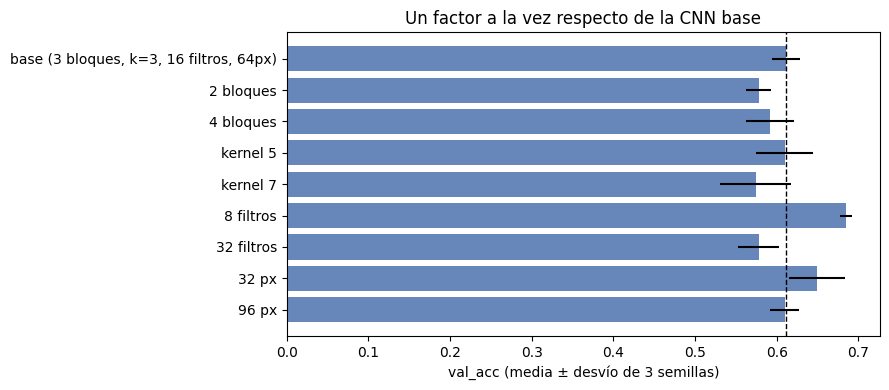

In [12]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional

| Variante | Campo receptivo | Parámetros | val_acc | Δ vs base | train_acc | Brecha | s/época |
|---|---|---|---|---|---|---|---|
| base (3 bloques, k=3, 16 filtros, 64 px) | 18 | 549.273 | 0.611 ± 0.017 | — | 0.907 | 0.296 | 0.42 |
| 2 bloques | 8 | 1.055.001 | 0.578 ± 0.016 | −3.3 | 0.740 | 0.163 | 0.38 |
| 4 bloques | 38 | 361.113 | 0.592 ± 0.029 | −2.0 | 0.770 | 0.178 | 0.46 |
| kernel 5 | 32 | 591.001 | 0.610 ± 0.035 | −0.2 | 0.789 | 0.179 | 0.55 |
| kernel 7 | 46 | 653.593 | 0.574 ± 0.043 | −3.7 | 0.771 | 0.197 | 0.75 |
| **8 filtros** | 18 | **269.521** | **0.684 ± 0.007** | **+7.3** | 0.878 | 0.194 | **0.20** |
| 32 filtros | 18 | 1.143.337 | 0.578 ± 0.025 | −3.3 | 0.749 | 0.171 | 1.05 |
| 32 px | 18 | 156.057 | 0.649 ± 0.034 | +3.8 | 0.827 | 0.178 | 0.12 |
| 96 px | 18 | 1.204.633 | 0.610 ± 0.017 | −0.2 | 0.736 | 0.126 | 1.02 |

**1. Qué supera el ruido.** El desvío entre semillas va de 0.007 a 0.043 y el error estándar de la validación es ±0.038.
- **8 filtros (+7,3 puntos)** es el único cambio claro. Supera ampliamente el desvío de las dos configuraciones (0.007 y 0.017): las 3 semillas de 8 filtros quedan por encima de la media de la base. Igual, la diferencia es ~1,9 errores estándar de la validación, y es la mejor de 9 variantes medidas sobre la misma validación, así que hay algo de sesgo optimista.
- **32 px (+3,8)** tiene la misma magnitud que su propio desvío (0.034): **no es concluyente**.
- **2 bloques, 32 filtros y kernel 7 (−3,3 a −3,7)** están en el orden del desvío (0.016–0.043) y por debajo del error estándar: indican una tendencia a empeorar, pero no son concluyentes.
- **Kernel 5, 96 px y 4 bloques (−0,2 a −2,0)** son indistinguibles de la base.

El patrón común es que **ninguna variante más grande mejoró, y la más chica fue la mejor**. Con 506 imágenes de train el problema está limitado por la **cantidad de datos**, no por la capacidad del modelo. Todas las variantes llegan a train_acc de 0.74–0.91 con val_acc ≈ 0.6, y el modelo con menos parámetros (8 filtros) tiene una buena val_acc con el menor desvío.

**2. Profundidad y kernel: campo receptivo vs. lo que hay que detectar.** Una lesión tiene información a varias escalas:
- **local**: bordes, red de pigmento, puntos, vasos (unos pocos píxeles);
- **media**: texturas;
- **global**: forma, asimetría y regularidad del borde (casi toda la imagen).

Con 3 bloques y k = 3 el campo receptivo es de 18 px, un 28% del lado de 64 px. Lo esperable era que ampliarlo (4 bloques: 38 px, 59%; kernel 7: 46 px, 72%) permitiera captar la forma global y mejorara. **No se observó**: 4 bloques −2,0 y kernel 7 −3,7, los dos dentro del ruido. Hay tres razones:
- La `Linear` de la cabeza **ya ve todo el mapa de 8×8**, así que la información global se combina igual, aunque cada neurona convolucional sea local.
- Kernels más grandes agregan parámetros por filtro (k = 7 tiene 5,4 veces más pesos convolucionales que k = 3) que con tan pocos datos se ajustan peor.
- Con **2 bloques** el campo receptivo baja a 8 px (solo patrones muy locales) y además la `Linear` crece a 1,05 M parámetros (32 canales × 16 × 16 = 8.192 entradas). Tiene la peor combinación: menos contexto y más parámetros para memorizar.

**Costo vs. ganancia:**
- Kernel 7 cuesta **1,8 veces más tiempo por época** (0.75 contra 0.42 s) sin ganancia.
- 32 filtros cuesta **2,5 veces más** (1.05 s) y tiene el doble de parámetros, con −3,3 puntos.
- 8 filtros es el **más barato** (0.20 s/época, la mitad de la base) y el mejor.

**3. Resolución de entrada (32/64/96 px).** Las convoluciones no dependen de la resolución, pero la `Linear` de la cabeza sí: recibe $64 \cdot (S/8)^2$ entradas.

| Resolución | Mapa final | Entradas de la `Linear` | Parámetros de la `Linear` | Campo receptivo / lado |
|---|---|---|---|---|
| 32 px | 4×4 | 1.024 | 131.200 | 56% |
| 64 px | 8×8 | 4.096 | 524.416 | 28% |
| 96 px | 12×12 | 9.216 | 1.179.776 | 19% |

- **Qué se gana con más resolución:** más detalle (red de pigmento, vasos finos, bordes nítidos).
- **Qué se pierde:**
  - cómputo: 96 px cuesta 2,4 veces más por época que 64 px (1.02 contra 0.42 s) y 8 veces más que 32 px;
  - parámetros: la `Linear` crece con el cuadrado del lado;
  - contexto: el campo receptivo de 18 px cubre una fracción cada vez menor de la lesión.

En los resultados, 96 px no mejora (0.610) y 32 px tiende a ser mejor (0.649, no concluyente). **Límite del experimento:** con ~60 imágenes por clase en train, el detalle extra de 96 px no se puede aprovechar, porque no hay suficientes ejemplos para aprender features finas sin memorizar. Además, la arquitectura queda fija (3 bloques), así que a 96 px el campo receptivo relativo es más chico. Una comparación justa ajustaría la profundidad a la resolución (más bloques a 96 px). También influye el sesgo de fuente del EDA: hay imágenes originales de 294 px que se *agrandan* a 96 px sin agregar información real.

**4. Qué no se puede concluir con "un factor a la vez" y 3 semillas.**
- **Interacciones.** Que 8 filtros sea mejor a 64 px no dice que siga siéndolo con otra profundidad, resolución o augmentation. La combinación de los mejores factores no garantiza ser la mejor (de hecho, en la sección 8 la config final con 8 filtros + flips dio 0.669 ± 0.021, sin mejorar a 8 filtros solo).
- **Óptimos fuera de la grilla.** No se exploraron, por ejemplo, 4 filtros o 48 px.
- **Ruido.** Con 3 semillas el desvío está mal estimado (podría ser bastante mayor o menor), y todas las variantes usan **la misma partición**: el ruido del split no se mide.
- **Sesgo de selección.** Elegir el máximo entre 9 variantes sobre 169 imágenes de validación sobreestima la accuracy del ganador.
- **Hiperparámetros fijos** (lr = 3·10⁻³, dropout 0.2, batch 32). Pueden favorecer a unas arquitecturas sobre otras; con otro lr quizás la red de 32 filtros rinda mejor.


## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6114,0.0170,0.9071,0.2957,1.0219,17.3333,0.4179,11.4311
1,flips,1518,0.6174,0.0228,0.7958,0.1784,1.0398,8.6667,1.2634,23.5463
2,flips+rot90,1518,0.5957,0.0218,0.7036,0.1079,1.0727,5.6667,1.2246,19.1500
3,flips+rot90+color,1518,0.5858,0.0221,0.7589,0.1731,1.0943,8.0000,1.2268,22.0806


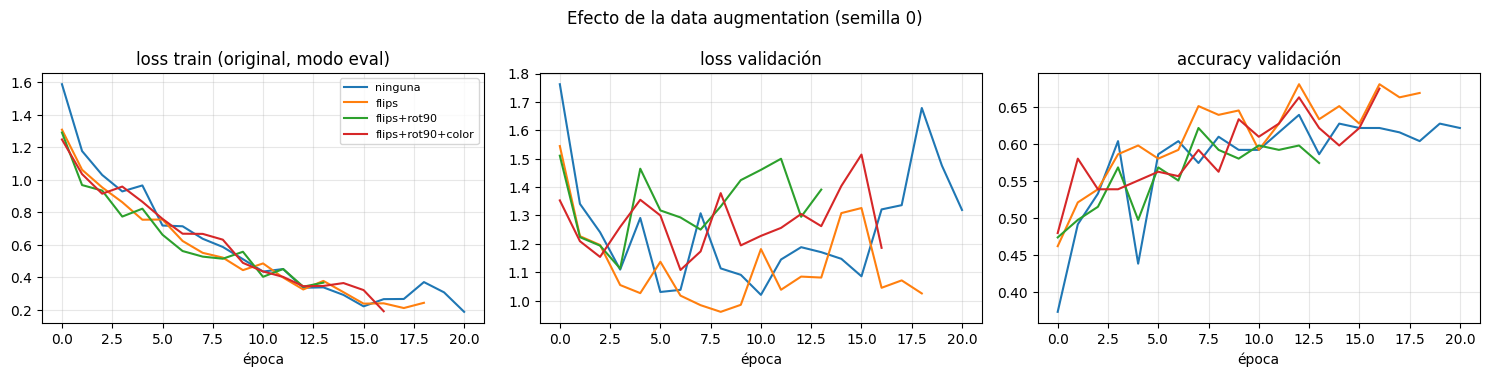

In [13]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation

**1. Overfitting sin augmentation.** La CNN base (3 semillas) llega a **train_acc 0.907 contra val_acc 0.611**: una **brecha de 0.296**, la mayor de todos los experimentos. En la curva de la semilla 0 (chequeo de la sección 4.2):
- la loss de train baja de forma casi continua, de 1.6 a ~0.2;
- la **val_loss** baja hasta ~1.03 en la época 6, oscila y alcanza su mínimo (~1.02) en la **época 11**, que es la mejor época del early stopping (val_acc 0.592, train_acc 0.862);
- **a partir de ahí sube**: 1.13–1.16 en las épocas 12–16 y un pico de **1.68 en la época 18**. El entrenamiento se corta en la época 21 por la paciencia de 10.

El modelo sigue mejorando en train mientras empeora en validación: con 506 imágenes y 549 k parámetros memoriza el train.

**2. Efecto de cada nivel de augmentation** (train = 506 originales + 2 copias aumentadas = 1.518 imágenes).

| Augmentation | val_acc | Brecha | val_loss mín. | Mejor época | s/época | Tiempo total |
|---|---|---|---|---|---|---|
| ninguna | 0.611 ± 0.017 | 0.296 | 1.022 | 17.3 | 0.42 | 11.4 s |
| flips | **0.617 ± 0.023** | 0.178 | 1.040 | 8.7 | 1.26 | 23.5 s |
| flips + rot90 | 0.596 ± 0.022 | **0.108** | 1.073 | 5.7 | 1.22 | 19.2 s |
| flips + rot90 + color | 0.586 ± 0.022 | 0.173 | 1.094 | 8.0 | 1.23 | 22.1 s |

- **Brecha.** Es lo que más cambia: baja de 0.296 a 0.178 con flips y a **0.108** con flips + rot90. Cuesta más memorizar un train con versiones transformadas de cada imagen. Por eso baja la train_acc (medida sobre las originales): 0.907 → 0.796 → 0.704.
- **val_acc y val_loss.** **No mejoran.** Flips da +0,6 puntos, flips + rot90 −1,6 y + color −2,6, todos menores que el desvío entre semillas (≈ 0.02) y que el error estándar (±0.038). La val_loss mínima incluso empeora levemente (1.022 → 1.094). **Ninguna mejora supera el ruido.** La augmentation redujo el overfitting medido como brecha, pero no se tradujo en mejor generalización: con solo 2 copias fijas por imagen, la diversidad agregada es limitada.
- **Época de convergencia.** Baja (17.3 → 5.7–8.7 épocas). Cada época tiene 3 veces más imágenes, es decir 3 veces más actualizaciones de pesos, así que se llega antes al mejor punto medido en épocas.
- **Tiempo.** Cada época cuesta **unas 3 veces más** (0.42 → 1.22–1.26 s) porque el train tiene 3 veces más imágenes (1.518 contra 506). No es por calcular las transformaciones, que se generan una sola vez antes de entrenar. El tiempo total se duplica (11 → 19–24 s), porque se necesitan menos épocas pero cada una es más cara.

**3. Desde la dermatología.**
- **Tienen sentido:** flips y rotaciones. Una lesión vista con dermatoscopio no tiene orientación privilegiada: rotada o espejada sigue siendo la misma lesión y conserva su diagnóstico. También pequeños desplazamientos y recortes que no corten la lesión.
- **Pueden destruir información:**
  - **El color**, que es diagnóstico: el azul-gris del velo del melanoma, el rojo de las lesiones vasculares, los marrones de la red de pigmento. Alterar brillo y contraste puede borrar justamente esas diferencias. Fue la variante con peor val_acc y peor val_loss, aunque dentro del ruido.
  - **La escala:** el tamaño de la lesión y de sus estructuras es información clínica, así que un zoom fuerte la altera.
- **Otras augmentations que probaría:**
  - rotaciones de ángulo arbitrario con recorte;
  - recortes aleatorios moderados (*random resized crop* con escala 0.8–1);
  - deformaciones elásticas suaves;
  - augmentation **en línea**, una transformación nueva en cada época en vez de 2 copias fijas;
  - **desenfoque y recompresión JPEG** aplicados también a las imágenes de alta resolución, para que la nitidez deje de delatar la fuente (el sesgo visto en el EDA);
  - agregar o quitar pelos sintéticos, que aparecen como artefactos en las dermatoscopías.

**4. Por qué después del split y solo en train.** Una imagen aumentada es casi la misma imagen. Si se aumentara **antes** de dividir, una lesión podría quedar en train y su versión rotada en validación o test. Es el mismo problema que los duplicados del EDA: la evaluación mediría memoria y no generalización, y la val_acc y la test_acc saldrían **infladas**. Además, las decisiones tomadas con validación favorecerían a los modelos que más memorizan. Val y test tampoco se aumentan porque tienen que representar la distribución real de imágenes que va a ver el modelo, y aumentarlos cambiaría lo que se mide.

**5. Comparación con el TP3.**
- **Dropout y L2** regularizan **restringiendo el modelo**: penalizan pesos grandes o apagan neuronas al azar. No agregan información sobre el problema; limitan cuánto puede memorizar la red.
- **La augmentation** regulariza **agregando datos**: le dice a la red, con ejemplos, qué transformaciones no deberían cambiar la clase. Le enseña invarianzas del dominio.

En el TP3, L2 controló el sobreajuste a costa de accuracy, y dropout fue lo único que mejoró sin costo de tiempo. Acá la augmentation redujo mucho la brecha (0.296 → 0.108), pero no mejoró la validación, y triplicó el tiempo por época. En cambio, dropout y BatchNorm prácticamente no costaban tiempo, y L2 agregaba ~40%.


## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [14]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips'}
Config final en validación: val_acc 0.669 ± 0.021 | brecha 0.146 | mejor época 5.3 | 9s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6710,0.0247,0.6608,0.0289,9.5207
1,MLP 64px,6358793,0.4959,0.0543,0.4811,0.0559,6.9721


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.67      0.30      0.41        20
         Atopic Dermatitis       0.71      0.94      0.81        16
          Benign keratosis       0.79      0.95      0.86        20
            Dermatofibroma       0.64      0.45      0.53        20
         Melanocytic nevus       0.61      0.55      0.58        20
                  Melanoma       0.45      0.50      0.48        20
   Squamous cell carcinoma       0.42      0.55      0.48        20
Tinea Ringworm Candidiasis       0.71      0.77      0.74        13
           Vascular lesion       0.90      0.95      0.93        20

                  accuracy                           0.65       169
                 macro avg       0.66      0.66      0.65       169
              weighted avg       0.65      0.65      0.64       169



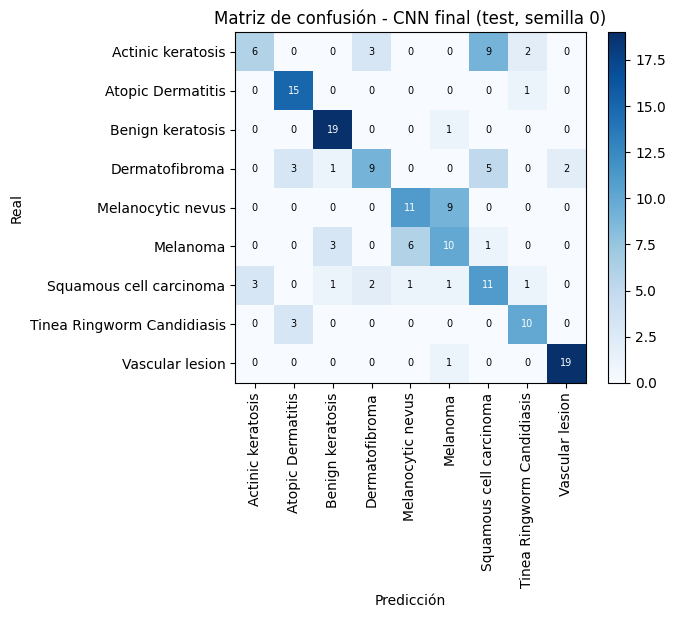

In [15]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

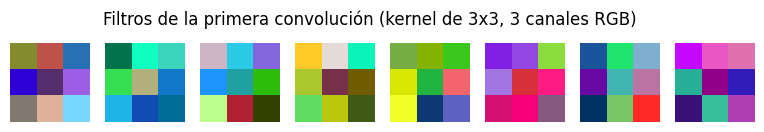

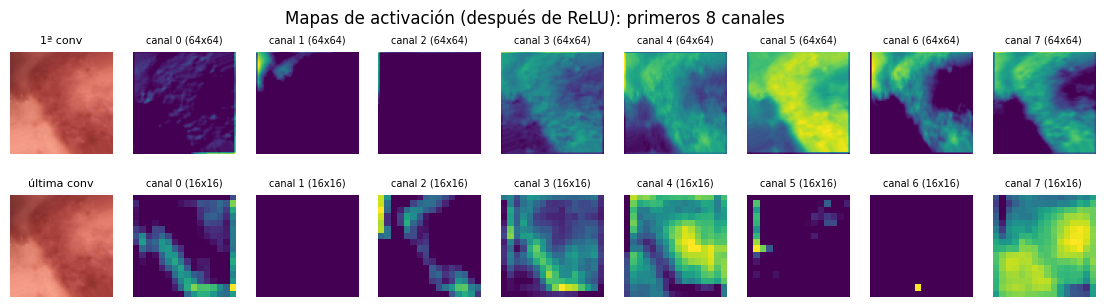

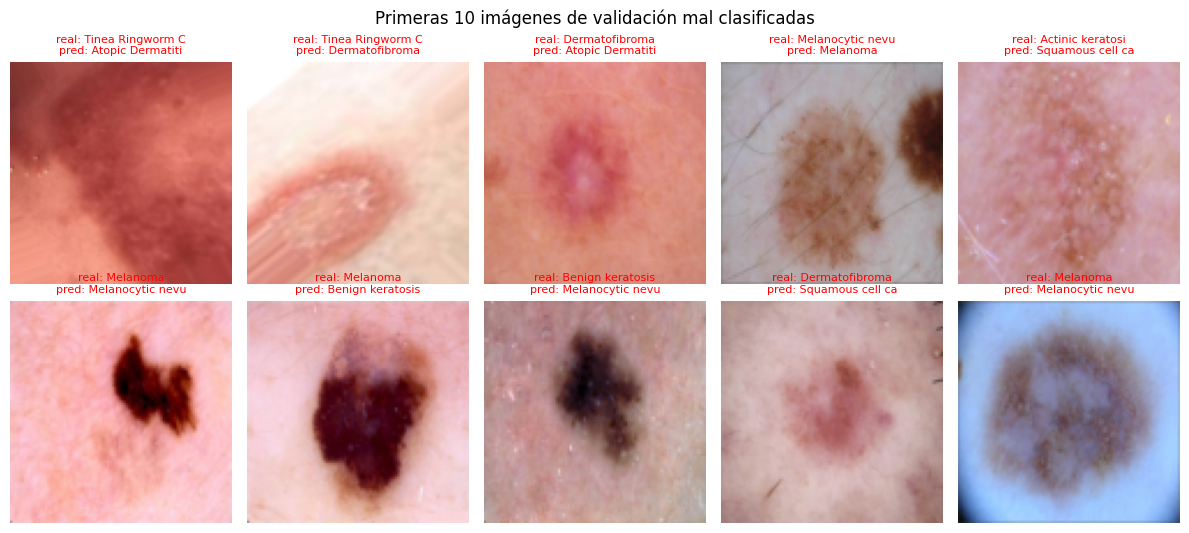

In [16]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación

**Configuración final.** Se eligió con validación de forma *greedy*: la mejor arquitectura fue **8 filtros** (0.684) y la mejor augmentation, **flips** (0.617). La combinación (3 bloques, k = 3, 8 filtros, 64 px, flips) dio en validación **0.669 ± 0.021**, con brecha 0.146 y mejor época 5.3. No mejora a "8 filtros" sin augmentation (−1,5 puntos, dentro del ruido): la combinación de los mejores factores no es necesariamente mejor que cada uno. No se usó `FINAL_OVERRIDE` ni se cambió ninguna constante de la sección 0.

**1. Consistencia val vs. test.** En test (5 semillas) la CNN final obtuvo **0.671 ± 0.025**, prácticamente igual a la validación (0.669 ± 0.021), con una diferencia mucho menor que el error estándar del test (±0.036). Por la selección sobre validación esperábamos un **sesgo optimista**: el máximo entre 9 arquitecturas, 8 filtros con 0.684, es justamente el mejor por haber sido elegido. Eso se refleja en que la configuración final quedó por debajo de ese 0.684. La coincidencia entre val y test indica que la validación no estaba muy inflada. Con 169 imágenes en cada partición, las dos estimaciones tienen un margen de ±3,6–3,8 puntos.

**2. CNN vs. MLP en test.**

| Modelo | Parámetros | test_acc | F1 macro | Tiempo de entrenamiento |
|---|---|---|---|---|
| CNN final | 269.521 | **0.671 ± 0.025** | **0.661 ± 0.029** | 9.5 s |
| MLP 64 px | 6.358.793 | 0.496 ± 0.054 | 0.481 ± 0.056 | 7.0 s |

La diferencia, **+17,5 puntos** de accuracy y +18 de F1 macro, es ~5 errores estándar del test y varias veces el desvío entre semillas: es **clara**. Además, la CNN usa **24 veces menos parámetros** y tiene la mitad de variabilidad entre semillas. Solo tarda algo más en entrenar (9.5 contra 7.0 s, porque la MLP corta antes por early stopping). **El costo se justifica ampliamente:** mejor accuracy, menos parámetros y más estabilidad, por 2,5 s más de entrenamiento.

**3. Matriz de confusión y reporte por clase** (semilla 0, accuracy 0.65).
- **Clases bien resueltas:**
  - Vascular lesion: F1 0.93 (recall 19/20), por el color rojo y las estructuras vasculares muy distintivas.
  - Benign keratosis: F1 0.86 (19/20).
  - Atopic Dermatitis: F1 0.81 (15/16).
  - Tinea: F1 0.74 (10/13).
- **Confusiones principales:**
  - **Actinic keratosis → Squamous cell carcinoma (9 de 20).** AK tiene el peor recall (0.30). Clínicamente es razonable: la queratosis actínica es una lesión precursora del carcinoma escamoso y comparten aspecto (escamas, eritema, superficie rugosa). También se confunde SCC → AK (3).
  - **Melanocytic nevus ↔ Melanoma (9 nevus predichos como melanoma y 6 melanomas como nevus).** Es la confusión clásica de la dermatología: ambas son lesiones melanocíticas pigmentadas, y distinguirlas depende de detalles finos (asimetría, irregularidad del borde, variedad de colores) que a 64 px y con ~60 ejemplos por clase se pierden. Además, 3 melanomas se predijeron como queratosis benigna.
  - **Dermatofibroma** se dispersa: 5 a SCC, 3 a Atopic Dermatitis, 2 a Vascular lesion.
  - **Tinea → Atopic Dermatitis (3).** Son las dos clases de fotos clínicas.

**No todos los errores son igual de graves.** Un **melanoma clasificado como nevus** (falso negativo de un cáncer potencialmente mortal) es mucho más grave que un **nevus clasificado como melanoma** (falso positivo que lleva a una biopsia innecesaria). Lo mismo vale para SCC predicho como lesión benigna. Acá el **recall de melanoma es 0.50**: la mitad de los melanomas del test no se detectan, inaceptable para un uso clínico aunque la accuracy global sea 0.65.

**Métricas relevantes:**
- el **recall (sensibilidad) de las clases malignas**, sobre todo melanoma, o la sensibilidad de una agrupación maligno vs. benigno;
- acompañado del **F1 macro**, que pondera todas las clases por igual y no deja que las clases fáciles escondan a las difíciles.

La accuracy trata igual todos los errores, que es justo lo que no corresponde en este problema.

**4. Filtros, mapas de activación y errores.**
- **Filtros de la primera convolución.** Los 8 filtros de 3×3 son patrones de **color** (combinaciones opuestas como verde/magenta, amarillo/azul) y de **bordes** (cambios de intensidad dentro del 3×3). Detectan contraste de color y transiciones locales, el nivel más bajo de features.
- **Mapas de la primera capa** (64×64). Conservan la geometría de la imagen: algunos canales responden a la **lesión** (zona oscura), otros a la **piel** alrededor y otros al **borde** de la lesión. Son todavía casi "filtros de imagen".
- **Mapas de la última capa** (16×16). Tienen menor resolución, son más **esparsos** (varios canales quedan casi en cero para esta imagen) y más abstractos: activan manchas en regiones puntuales, combinando bordes y colores de capas anteriores en patrones de textura o partes de la lesión.
- **Errores** (primeras 10 imágenes mal clasificadas de validación). Se repiten los pares de la matriz de confusión:
  - 5 de las 10 son confusiones entre melanoma, nevus y queratosis benigna: lesiones pigmentadas oscuras;
  - AK → SCC y DF → SCC: lesiones rosadas de bajo contraste, sin bordes nítidos;
  - Tinea → Atopic, Tinea → DF y DF → Atopic: fotos clínicas o primeros planos de piel.

  Varias son imágenes con poco contraste entre lesión y piel. Un melanoma con el **borde circular del dermatoscopio** (viñeta oscura y halo azulado) se predijo como nevus.

**5. Sesgos y limitaciones.**
- **Sesgo de fuente.** El EDA mostró que la **resolución identifica casi perfectamente la clase**: 600×450 son cuatro clases enteras y 294×222 es toda Atopic. También mostró que Atopic y Tinea son **fotos clínicas**, con otro color y encuadre. La red puede usar esas señales (nitidez, artefactos, iluminación, fondo) en vez de la lesión. Es llamativo que Atopic (F1 0.81) y Tinea (0.74) estén entre las mejores clases, por encima de clases dermatoscópicas, y que se confundan sobre todo entre sí. No se puede saber qué parte de su accuracy viene de la lesión y qué parte de reconocer "foto clínica". Esos números probablemente están **inflados** respecto de lo que el modelo lograría con imágenes de otra fuente.
- **Duplicados.** Se eliminaron (34 pares), pero solo los exactos y los casi-idénticos. Imágenes distintas del mismo paciente o de la misma lesión podrían seguir repartidas entre particiones; el dataset no trae identificadores de paciente para controlarlo.
- **Tamaño.** Hay 506 imágenes de train (38–60 por clase) y 169 en val y en test. Cada accuracy tiene un error estándar de ±3,6–3,8 puntos, así que solo diferencias grandes son detectables.
- **Una sola partición y pocas semillas.** Todo se midió sobre el mismo split. Las 3 semillas (5 en la evaluación final) solo capturan el ruido de inicialización, no el de la partición.
- **Con más tiempo haría lo siguiente:**
  - validación cruzada estratificada (k-fold) y más semillas;
  - un experimento para medir el sesgo de fuente: igualar resolución, nitidez y compresión, o evaluar con imágenes de otra fuente;
  - más datos del ISIC completo, y *transfer learning* con una red preentrenada;
  - augmentation en línea;
  - pesos por clase en la loss, o un umbral de decisión, para priorizar el recall de melanoma;
  - reportar la sensibilidad maligno/benigno como métrica principal.


## Declaración de uso de IA

Sí, usé **Claude (Anthropic)** como asistente en este TP:
- **Código:** no modifiqué el código del notebook ni sus constantes. Usé la IA para diagnosticar un error de ejecución en Windows (rutas de más de 260 caracteres por los nombres largos de algunas imágenes de Tinea), que resolví moviendo el proyecto a una carpeta con una ruta más corta.
- **Redacción:** la IA redactó los borradores de algunas celdas a partir de los outputs de **mi** corrida del notebook. Principalmente aquellos que tenían graficos para poder determinar los numeros de ellos de manera precisa. También verificó los cálculos a mano (parámetros de cada capa, campo receptivo, parámetros de la `Linear` según la resolución) contra las tablas.
- **Verificación propia:** revisé los textos, comprobé que cada número citado coincida con los outputs y gráficos de esta corrida.
